In [1]:
from preprocessing import load_splits, build_preprocessor, rmse, FEATURES, TARGET
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
train_split, val_split = load_splits()
preprocessor = build_preprocessor()

X_train = preprocessor.fit_transform(train_split[FEATURES])
X_val = preprocessor.transform(val_split[FEATURES])

y_train = train_split[TARGET]
y_val = val_split[TARGET]

print("Training observations:", len(y_train))
print("Validation observations:", len(y_val))

Training observations: 5918
Validation observations: 1480


In [3]:
random_forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train, y_train)

rf_train_pred = random_forest.predict(X_train)
rf_val_pred = random_forest.predict(X_val)

rf_train_rmse = rmse(y_train, rf_train_pred)
rf_val_rmse = rmse(y_val, rf_val_pred)

print("Random Forest Training RMSE:", round(rf_train_rmse, 2))
print("Random Forest Validation RMSE:", round(rf_val_rmse, 2))

Random Forest Training RMSE: 159.59
Random Forest Validation RMSE: 453.36


In [4]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameters to test
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 3]
}

# Create GridSearchCV
rf_grid_search = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_grid=rf_param_grid,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)

# Train GridSearchCV using training data only
rf_grid_search.fit(X_train, y_train)

# Display the best results
print("Best Hyperparameters:", rf_grid_search.best_params_)
print("Best Cross-Validation RMSE:",
      round(-rf_grid_search.best_score_, 2))

Best Hyperparameters: {'max_depth': None, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 200}
Best Cross-Validation RMSE: 424.55


In [5]:
best_rf = rf_grid_search.best_estimator_

best_rf_train_pred = best_rf.predict(X_train)
best_rf_val_pred = best_rf.predict(X_val)

best_rf_train_rmse = rmse(y_train, best_rf_train_pred)
best_rf_val_rmse = rmse(y_val, best_rf_val_pred)

print("Tuned Random Forest Training RMSE:",
      round(best_rf_train_rmse, 2))

print("Tuned Random Forest Validation RMSE:",
      round(best_rf_val_rmse, 2))

Tuned Random Forest Training RMSE: 268.7
Tuned Random Forest Validation RMSE: 453.49


In [6]:
# Compare original and tuned Random Forest models
rf_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "Training RMSE": [
        rf_train_rmse,
        best_rf_train_rmse
    ],
    "Validation RMSE": [
        rf_val_rmse,
        best_rf_val_rmse
    ]
})

# Sort models by validation performance
rf_comparison = rf_comparison.sort_values(
    "Validation RMSE"
)

rf_comparison.round(2)

,Model,Training RMSE,Validation RMSE
0,Original Random Forest,159.59,453.36
1,Tuned Random Forest,268.70,453.49


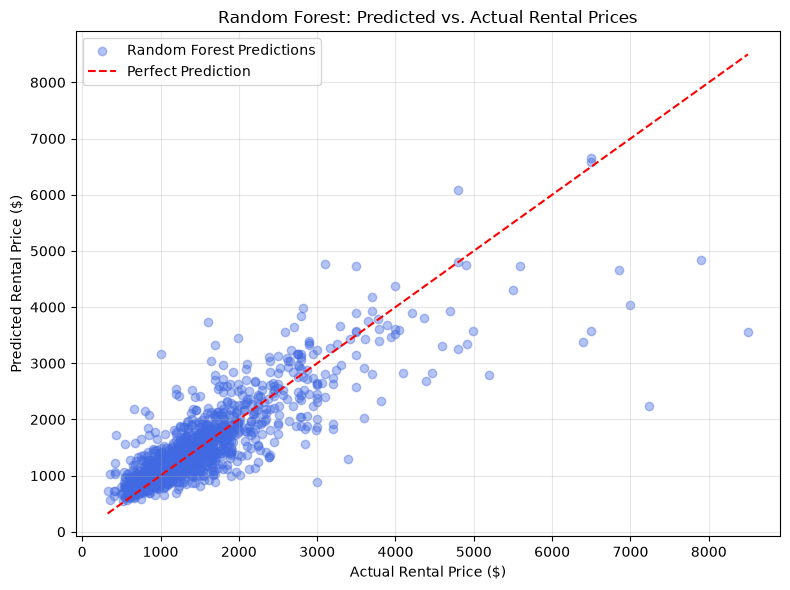

In [7]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    rf_val_pred,
    alpha=0.4,
    color="royalblue",
    label="Random Forest Predictions"
)

min_price = min(y_val.min(), rf_val_pred.min())
max_price = max(y_val.max(), rf_val_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Rental Price ($)")
plt.ylabel("Predicted Rental Price ($)")
plt.title("Random Forest: Predicted vs. Actual Rental Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Random Forest Model Evaluation

### Initial Model

I trained a Random Forest model using 100 decision trees to predict monthly apartment rental prices.

The model had a training RMSE of 159.59 and a validation RMSE of 453.36.

The difference between these results shows that the model has some overfitting. This means it predicts prices better for apartments it trained on than for new apartments.

However, the Random Forest performed better than our Linear Regression and Decision Tree models.

### Improving the Model with GridSearchCV

I used GridSearchCV to test different settings and find the best combination for the Random Forest.

The best settings were:
- 200 trees
- No maximum tree depth
- Minimum of 2 samples to split
- Minimum of 3 samples per leaf

The best cross-validation RMSE was **$424.55**.

After tuning, the model had a training RMSE of 268.70 and a validation RMSE of 453.49

The tuning helped reduce overfitting, but it did not improve the validation RMSE.

### Understanding the Graph

The graph compares the actual apartment rental prices with the prices predicted by the model.

Most predictions were fairly close to the actual prices. However, the model struggled more with some expensive apartments and often predicted prices lower than their actual rent.

### Conclusion

The original Random Forest performed slightly better, with a validation RMSE of 453.36 compared to 453.49 for the tuned model

Since the difference is very small, both models performed almost the same.

For now, I would choose the original Random Forest because it uses fewer trees and has a slightly lower validation RMSE.

We will compare it with the other models before choosing the best model for our final predictions.
